In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import OPTICS
from sklearn import metrics
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

In [6]:
df = pd.read_excel("nba_baru.xlsx")
df

,Unnamed: 0,Name,Team,Number,Position,Age,Height,Weight,College,Salary,Salarymissing,Collegemissing
0,0,Avery Bradley,Boston Celtics,0,PG,25,74,180,Texas,7730337,False,False
1,1,Jae Crowder,Boston Celtics,99,SF,25,78,235,Marquette,6796117,False,False
2,2,John Holland,Boston Celtics,30,SG,27,77,205,Boston University,2839073,True,False
3,3,R.J. Hunter,Boston Celtics,28,SG,22,77,185,Georgia State,1148640,False,False
4,4,Jonas Jerebko,Boston Celtics,8,PF,29,82,231,Kentucky,5000000,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
452,452,Trey Lyles,Utah Jazz,41,PF,20,82,234,Kentucky,2239800,False,False
453,453,Shelvin Mack,Utah Jazz,8,PG,26,75,203,Butler,2433333,False,False
454,454,Raul Neto,Utah Jazz,25,PG,24,73,179,Kentucky,900000,False,True
455,455,Tibor Pleiss,Utah Jazz,21,C,26,87,256,Kentucky,2900000,False,True


In [7]:
features1 = ["Height", "Weight"]

data = df [features1].copy()
data

,Height,Weight
0,74,180
1,78,235
2,77,205
3,77,185
4,82,231
...,...,...
452,82,234
453,75,203
454,73,179
455,87,256


In [8]:
# Compute DBSCAN
db = OPTICS(min_samples=2).fit(data)
labels = db.labels_
print(labels)

[  0  -1  24   4  -1  67  60  -1   7  44  91  -1  41  36  -1  -1   6  17
  41  18  35  44  95 104  -1  46  65  82  27  -1  31  45  25  68  18  35
  19  12  90  84  -1 105  60  15  68  23  89  -1  38  85  35  75  82  17
  19  54 104  94  23  28  47  76  29  -1  41  86   6  30  47  61  39  15
  67  83  90  -1  11  50  92  96   6 100  57  36  -1  45  67  42  89  37
 104  83  86  13  48  61  87  37 100  56  94  -1   2   8  17  13  88  86
  34  -1  -1  -1  18  54  55  86  13 102  93  -1  34  -1  26  35  -1  20
  39   5  92  54  95   7  72  79  56  -1  69  -1  31  64  51  71  94  -1
   1  45  56 101  13  -1  -1  86  99  41  55 104  85  51   4  50  46  -1
  58  54   6  -1  -1  -1  11  88  59  48  40  -1  87   0 104  43  48  -1
  -1  76  -1  -1   9  25  24  21 105  61  23  -1  79  32  61  68  89  86
   2  45   5  62  49  -1  83  57  -1  24  -1  83   0  80  18  10  12  11
  54  78  31  60 100  52  -1  88  83  40  22  64   3  -1  30   2  76  43
 102  77  73 104  -1  70  58  18  -1  62   1  -1  6

D:\anaconda\Lib\site-packages\sklearn\cluster\_optics.py:1084: RuntimeWarning: divide by zero encountered in divide
  ratio = reachability_plot[:-1] / reachability_plot[1:]


In [9]:
# Number of clusters in labels, ignoring noise if present.
core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)
n_noise_

78

In [10]:
print('Perkiraaan jumlah klaster: %d' % n_clusters_)
print('Jumlah titik noise: %d' % n_noise_)
print("Silhouette Coefficient: %0.3f"
      % metrics.silhouette_score(data, labels))

Perkiraaan jumlah klaster: 107
Jumlah titik noise: 78
Silhouette Coefficient: 0.522


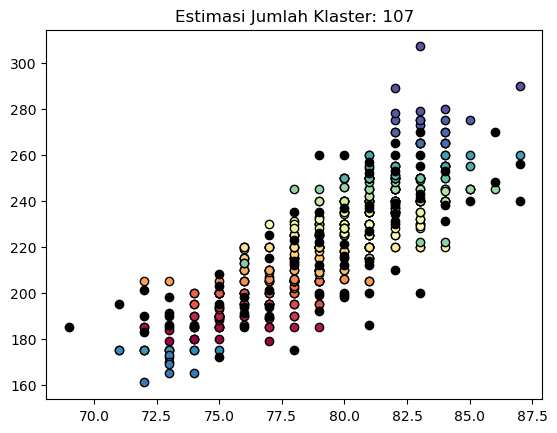

In [11]:
import matplotlib.pyplot as plt
%matplotlib inline

# Black removed and is used for noise instead.
unique_labels = set(labels)
colors = [plt.cm.Spectral(each)
          for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    xy = data[class_member_mask & core_samples_mask]
    plt.plot(xy.iloc[:, 0], xy.iloc[:, 1], 'o',
             markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=14)

    xy = data[class_member_mask & ~core_samples_mask]
    plt.plot(xy.iloc[:, 0], xy.iloc[:, 1], 'o',
             markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=6)

plt.title('Estimasi Jumlah Klaster: %d' % n_clusters_)
plt.show()


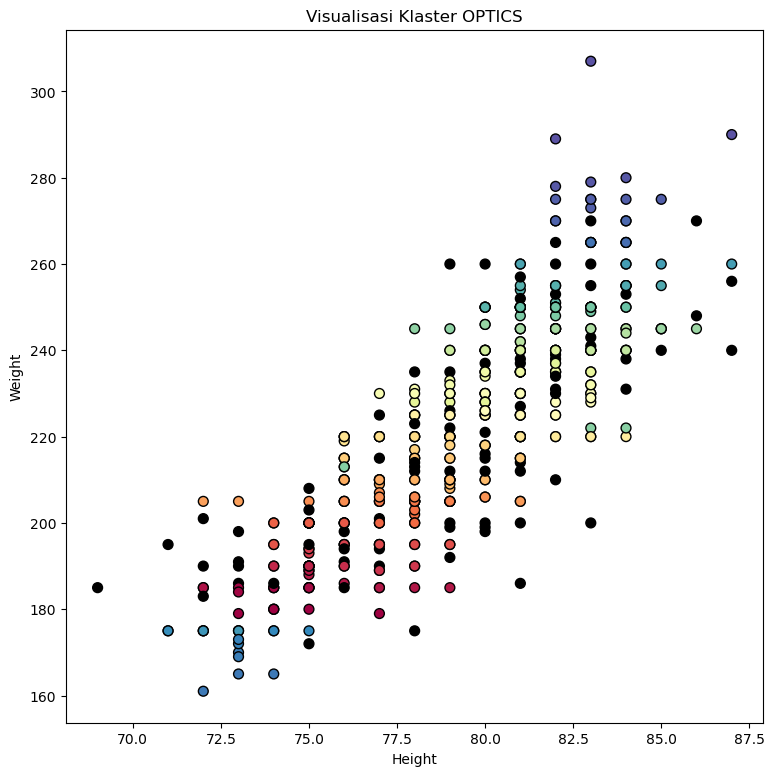

In [12]:
# Visualisasi dengan Colormap Dinamis
plt.figure(figsize=(9, 9))

# Building the colour vector for each data point using a colormap
unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

# Map each label to its corresponding color
colour_map = {k: col for k, col in zip(unique_labels, colors)}
colour_map[-1] = (0, 0, 0, 1) # Black for noise

cvec = [colour_map[label] for label in labels]

# Plotting Height on X-Axis and Weight on Y-Axis
plt.scatter(data.iloc[:, 0], data.iloc[:, 1], c=cvec, edgecolor='k', s=50)

plt.title('Visualisasi Klaster OPTICS')
plt.xlabel('Height')
plt.ylabel('Weight')
plt.show()